In [3]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
from scipy.integrate import odeint
from scipy.integrate import solve_ivp

# EDOs de primeria ordem

Fricção do ar ao cair

$$ \frac{d}{dt}v(t) = g -\frac{\alpha}{m} v^2(t)  \hspace{10mm} v(0) = 0$$

Observe que não há dependência do tempo neste exemplo em particular. Precisamos escrever esta equação diferencial em **forma python**

In [4]:
def dvdt(t, v):
    return 10- 0.3*v**2
v0 = 0

Resolva a equação diferencial. Existem dois solucionadores principais no scipy

* `odeint`: Bastante clássico, usa uma solução particular chamada lsoda da biblioteca FORTRAN odepack
* `solve_ivp`: Mais personalizável, pode escolher a partir de uma lista de possíveis solucionadores

In [6]:
tt = np.linspace(0, 1, 100)

In [7]:
sol_m1 = odeint(dvdt, y0=v0, t=tt, tfirst=True)
sol_m2 = solve_ivp(dvdt, t_span=(0,max(tt)), y0=[v0], t_eval=tt)

Veja a solução. Ficará óbvio por que ele é retornado desta forma quando lidarmos com sistemas de EDOs (para que esses solucionadores realmente servem)

In [20]:
sol_m1.T

array([[0.        , 0.05047933, 0.10080451, 0.15082334, 0.20038726,
        0.24935318, 0.29758502, 0.34495519, 0.39134576, 0.43664948,
        0.48077056, 0.52362515, 0.56514164, 0.60526086, 0.6439356 ,
        0.68113064, 0.71682205, 0.75099661, 0.78365109, 0.8147914 ,
        0.84443176, 0.87259378, 0.89930556, 0.92460079, 0.94851787,
        0.97109913, 0.99239002, 1.01243837, 1.03129376, 1.04900692,
        1.06562918, 1.081212  , 1.0958066 , 1.10946355, 1.12223249,
        1.13416195, 1.14529906, 1.15568941, 1.16537698, 1.17440397,
        1.18281086, 1.19063623, 1.19791686, 1.20468768, 1.21098179,
        1.21683053, 1.22226349, 1.22730856, 1.23199199, 1.23633849,
        1.24037122, 1.24411192, 1.24758094, 1.25079735, 1.25377896,
        1.25654241, 1.25910322, 1.2614759 , 1.26367394, 1.26570992,
        1.26759557, 1.26934179, 1.27095869, 1.27245574, 1.27384168,
        1.27512464, 1.2763122 , 1.27741137, 1.27842865, 1.27937009,
        1.28024128, 1.28104744, 1.28179338, 1.28

In [17]:
v_sol_m1 = sol_m1.T[0]
v_sol_m2 = sol_m2.y[0]

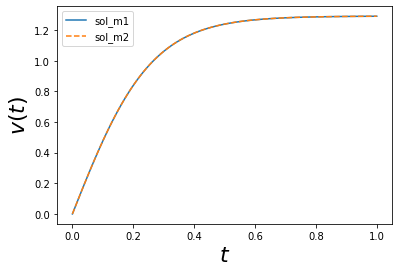

In [23]:
plt.plot(t, v_sol_m1, label='sol_m1')
plt.plot(t, v_sol_m2, '--', label='sol_m2')
plt.ylabel('$v(t)$', fontsize=22)
plt.xlabel('$t$', fontsize=22)
plt.legend()
plt.show()

# EDOs de primeira ordem acopladas

$$ y_1' = y_1 + y_2^2 + 3x \hspace{10mm} y_1(0)=0$$
$$ y_2' = 3y_1 + y_2^3 - \cos(x) \hspace{10mm} y_2(0)=0$$

Seja 
$$S=(y_1, y_2)$$

Escrevamos uma função que retorne 
$$\frac{dS}{dx} = ( \frac{dy_1}{dx}, \frac{dy_2}{dx} )$$

A função $dS/dx$ pode receber $S=(y_1, y_2)$ e $x$. Isso é como antes, mas em formato vetorial

$$ \vec{S} = \begin{bmatrix} y_1 \\ y_2 \end{bmatrix} \hspace{10mm} \implies  \hspace{10mm} \frac{d\vec{S}}{dx} = \vec{f}(x, \vec{S}) = \vec{f}(x, y_1, y_2) =  \begin{bmatrix} y_1' \\ y_2' \end{bmatrix}  = \begin{bmatrix}  y_1 + y_2^2 + 3x\\ 3y_1 + y_2^3 - \cos(x) \end{bmatrix}$$

In [ ]:
def dSdx(x, S):
    y1, y2 = S
    return [y1 + y2**2  + 3*x,
           3*y1 + y2**3 - np.cos(x)]
y1_0 = 0
y2_0 = 0
S_0 = (y1_0, y2_0)

**Resolva** esta EDO

In [ ]:
x = np.linspace(0, 1, 100)
sol = odeint(dSdx, y0=S_0, t=x, tfirst=True)

Obtenha $y_1$ e $y_2$ da solução

In [ ]:
y1_sol = sol.T[0]
y2_sol = sol.T[1]

And plot

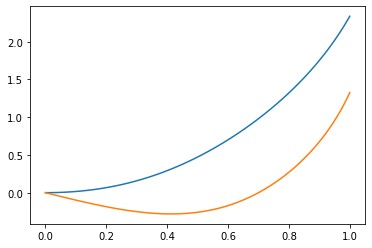

In [ ]:
plt.plot(x, y1_sol)
plt.plot(x, y2_sol)

# EDOs de segunda ordem

O **Python não possui funções para resolver diretamente EDOs de segunda ordem**.
* Mas **qualquer EDO de segunda ordem pode ser convertida em duas EDOs de primeira ordem**.

Considerar

$$\ddot{x} = -\dot{x}^2 + \sin(x)$$

Podemos converter isso em duas EDOs de primeira ordem da seguinte forma:

* Pegue $x$ (é isso que estamos tentando resolver). Em seguida, defina $\dot{x}=v$ para que $v$ se torne uma nova variável.
* Observe que $\dot{x}=v$ é uma equação diferencial
* Como $\dot{v} = \ddot{x} = -\dot{x}^2 + \sin(x) = -v^2 + \sin(x)$ obtemos outra equação diferencial

Nossas duas equações:

$$\dot{x} = v$$
$$\dot{v} = -v^2 + \sin(x)$$

Estas são duas equações de primeira ordem acopladas. Eles exigem uma condição inicial ($x_0$ e $v_0$)

In [ ]:
def dSdx(x, S):
    x, v = S
    return [v,
           -v**2 + np.sin(x)]
x_0 = 0
v_0 = 5
S_0 = (x_0, v_0)

In [ ]:
t = np.linspace(0, 1, 100)
sol = odeint(dSdx, y0=S_0, t=t, tfirst=True)

In [ ]:
x_sol = sol.T[0]
v_sol = sol.T[1]

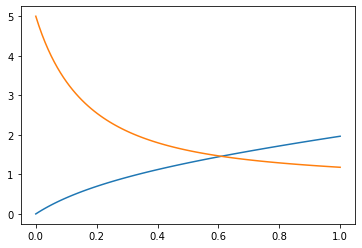

In [ ]:
plt.plot(t, x_sol)
plt.plot(t, v_sol)

This process can be repeated for third order (required defining two new variables) fourth order (requires defining three new variables) and so on...

**Exemplo:** duas equações de terceira ordem acopladas

$$\dddot{x_2}= -\ddot{x_1}^3 + \dot{x_2} + x_1 + \sin(t)$$
$$\dddot{x_1}= -2\dot{x_2}^2 + x_2$$

Definir
* $v_1 = \dot{x_1}$
* $v_2 = \dot{x_2}$
* $a_1 = \ddot{x_1} = \dot{v_1}$
* $a_2 = \ddot{x_2} = \dot{v_2}$

Estas formam quatro equações diferenciais. Então, observando que $\dot{a_1} = \dddot{x_1}$ e $\dot{a_2} = \dddot{x_2}$ temos

* $\dot{a_2} = -a_1^3 + v_2 + x_1 + \sin(t)$
* $\dot{a_1} = -2v_2^2 + x_2$

Então

$$\vec{S} = \begin{bmatrix} x_1\\ v_1 \\ a_1 \\ x_2 \\ v_2 \\ a_2 \end{bmatrix} \hspace{10mm} \implies \hspace{10mm} \frac{d \vec{S}}{dt} = \begin{bmatrix} \dot{x_1}\\ \dot{v_1} \\ \dot{a_1} \\ \dot{x_2} \\ \dot{v_2} \\ \dot{a_2} \end{bmatrix} = \begin{bmatrix} v_1\\ a_1 \\ -2v_2^2 + x_2 \\ v_2 \\ a_2 \\ -a_1^3 + v_2 + x_1 + \sin(t) \end{bmatrix}$$

In [ ]:
def dSdt(t, S):
    x1, v1, a1, x2, v2, a2 = S
    return [v1,
            a1,
            -2*v2**2 + x2,
            v2,
            a2,
            -a1**3 + v2 + v1 + np.sin(t)]
x1_0 = 0
v1_0 = 0
a1_0 = 0
x2_0 = 0
v2_0 = 0
a2_0 = 0
v_0 = 0
S_0 = (x1_0, v1_0, a1_0, x1_0, v1_0, a1_0)

In [ ]:
t = np.linspace(0, 1, 100)
sol = odeint(dSdt, y0=S_0, t=t, tfirst=True)